<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day07_Fairness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: fetch your code files if this is a fresh session
import os, subprocess
if not os.path.exists("matching.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/buntyedutainer/allocation-optimizer", "repo"])
    subprocess.run("cp repo/src/*.py .", shell=True)
print([f for f in ["matching.py", "datagen.py"] if os.path.exists(f)])
print("matching.py has the optimal method:", "def match_optimal" in open("matching.py").read())

['matching.py', 'datagen.py']
matching.py has the optimal method: True


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import datagen as D
import matching as M

def fairness(out):
    """out has one row per student, with their 'score' and the 'rank' they gave the project they got."""
    s = out["score"].sort_values()
    k = max(1, int(round(0.1 * len(s))))                      # the bottom 10% of students
    return {"average happiness": out["score"].mean(),
            "bottom 10% average": s.iloc[:k].mean(),
            "lowest happiness": s.iloc[0],
            "unhappy % (rank 4 or worse)": 100 * (out["rank"] >= 4).mean(),
            "worst rank": out["rank"].max(),
            "spread (std)": out["score"].std()}

HIGHER = {"average happiness": True, "bottom 10% average": True, "lowest happiness": True,
          "unhappy % (rank 4 or worse)": False, "worst rank": False, "spread (std)": False}
METRICS = list(HIGHER)

In [4]:
def collect(seed, n_lineups=20):
    inst = D.build_instance(seed)
    score, rank_table, capacity, students = inst["score"], inst["rank_table"], inst["capacity"], inst["students"]
    rng = np.random.default_rng(seed + 2000)

    opt = M.outcomes(M.match_optimal(score, rank_table, capacity), score, rank_table).reindex(score.index)
    g_fair, g_scores, g_ranks, g_pos = [], [], [], []
    for _ in range(n_lineups):
        order = list(rng.permutation(score.index))
        out = M.outcomes(M.match_greedy(score, rank_table, capacity, order), score, rank_table)
        g_fair.append(fairness(out))
        g_scores.append(out["score"].reindex(score.index))
        g_ranks.append(out["rank"].reindex(score.index))
        g_pos.append(out.loc[order, "score"].values)               # happiness by position in the line

    return {"seed": seed, "students": students, "opt": opt, "opt_fair": fairness(opt),
            "greedy_fair": pd.DataFrame(g_fair).mean().to_dict(),
            "greedy_score": pd.concat(g_scores, axis=1).mean(axis=1),
            "greedy_rank": pd.concat(g_ranks, axis=1).mean(axis=1),
            "greedy_by_position": np.mean(g_pos, axis=0)}

SEEDS = list(range(100, 130))
t0, data = time.time(), []
for i, s in enumerate(SEEDS, 1):
    data.append(collect(s))
    if i % 10 == 0:
        print(f"{i} of {len(SEEDS)} datasets done ({time.time() - t0:.0f} seconds)")

10 of 30 datasets done (9 seconds)
20 of 30 datasets done (18 seconds)
30 of 30 datasets done (28 seconds)


In [5]:
opt_f = pd.DataFrame([d["opt_fair"] for d in data], index=SEEDS)
gr_f = pd.DataFrame([d["greedy_fair"] for d in data], index=SEEDS)

def mean_sd(df):
    return (df.mean().round(1).astype(str) + " ± " + df.std().round(1).astype(str))

print("Average over 30 datasets ± how much it varies from dataset to dataset")
display(pd.DataFrame({"Greedy": mean_sd(gr_f), "Optimal": mean_sd(opt_f)}))

def interval(diff, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    wobble = [rng.choice(diff.values, len(diff)).mean() for _ in range(n)]
    return np.percentile(wobble, [2.5, 97.5])

rows = []
for m in METRICS:
    diff = opt_f[m] - gr_f[m]
    better = (diff > 1e-9) if HIGHER[m] else (diff < -1e-9)
    lo, hi = interval(diff)
    rows.append({"measure": m, "good direction": "higher" if HIGHER[m] else "lower",
                 "Optimal minus Greedy": round(diff.mean(), 2), "95% interval": f"{lo:.2f} to {hi:.2f}",
                 "Optimal better in": f"{int(better.sum())} of 30", "clearly different?": "yes" if (lo > 0 or hi < 0) else "no"})
paired = pd.DataFrame(rows)
paired

Average over 30 datasets ± how much it varies from dataset to dataset


,Greedy,Optimal
average happiness,4.9 ± 0.2,5.7 ± 0.2
bottom 10% average,1.1 ± 0.1,1.9 ± 0.3
lowest happiness,0.7 ± 0.2,1.5 ± 0.4
unhappy % (rank 4 or worse),57.5 ± 3.7,45.5 ± 5.2
worst rank,6.0 ± 0.0,6.0 ± 0.0
spread (std),2.6 ± 0.1,2.4 ± 0.1


,measure,good direction,Optimal minus Greedy,95% interval,Optimal better in,clearly different?
0,average happiness,higher,0.86,0.84 to 0.89,30 of 30,yes
1,bottom 10% average,higher,0.79,0.68 to 0.90,30 of 30,yes
2,lowest happiness,higher,0.77,0.63 to 0.90,29 of 30,yes
3,unhappy % (rank 4 or worse),lower,-12.02,-13.16 to -10.88,30 of 30,yes
4,worst rank,lower,0.00,0.00 to 0.00,0 of 30,no
5,spread (std),lower,-0.13,-0.17 to -0.09,28 of 30,yes


In [6]:
rows = []
for d in data:
    diff = d["opt"]["score"] - d["greedy_score"]
    rows.append({"seed": d["seed"], "gain over 1 point %": 100 * (diff > 1).mean(),
                 "loss over 1 point %": 100 * (diff < -1).mean(),
                 "largest gain": diff.max(), "largest loss": diff.min()})
wl = pd.DataFrame(rows)

print("Across 30 datasets, per student, Optimal compared with their average Greedy outcome:")
print(f"  students who gain more than 1 happiness point : {wl['gain over 1 point %'].mean():.1f}%")
print(f"  students who lose more than 1 happiness point : {wl['loss over 1 point %'].mean():.1f}%")
print(f"  largest single gain: {wl['largest gain'].max():.1f} | largest single loss: {wl['largest loss'].min():.1f}")

d0 = data[0]
diff0 = (d0["opt"]["score"] - d0["greedy_score"]).sort_values()
print("\nDataset", d0["seed"], ": the five students who lose most under Optimal")
print(pd.DataFrame({"Greedy average": d0["greedy_score"][diff0.index[:5]].round(1),
                    "Optimal": d0["opt"]["score"][diff0.index[:5]], "change": diff0[:5].round(1)}))

Across 30 datasets, per student, Optimal compared with their average Greedy outcome:
  students who gain more than 1 happiness point : 42.3%
  students who lose more than 1 happiness point : 27.8%
  largest single gain: 6.6 | largest single loss: -4.6

Dataset 100 : the five students who lose most under Optimal
     Greedy average  Optimal  change
S25             5.4      1.5    -3.9
S11             4.9      1.5    -3.4
S39             5.0      2.0    -3.0
S35             4.1      1.5    -2.6
S36             4.1      1.5    -2.6


Greedy, average happiness of the first 10 in line: 7.94
Greedy, average happiness of the last 10 in line:  2.30
The gap is positive in 30 of 30 datasets
For comparison, Optimal's average happiness: 5.75


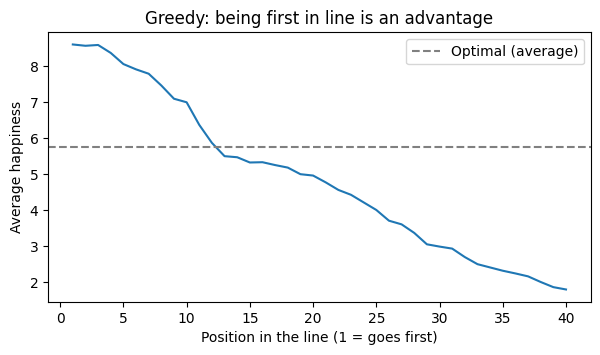

In [7]:
pos = np.array([d["greedy_by_position"] for d in data])           # 30 datasets x 40 positions
first10, last10 = pos[:, :10].mean(axis=1), pos[:, -10:].mean(axis=1)
print(f"Greedy, average happiness of the first 10 in line: {first10.mean():.2f}")
print(f"Greedy, average happiness of the last 10 in line:  {last10.mean():.2f}")
print(f"The gap is positive in {(first10 > last10).sum()} of 30 datasets")
print(f"For comparison, Optimal's average happiness: {opt_f['average happiness'].mean():.2f}")

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, 41), pos.mean(axis=0))
plt.axhline(opt_f["average happiness"].mean(), color="gray", linestyle="--", label="Optimal (average)")
plt.xlabel("Position in the line (1 = goes first)")
plt.ylabel("Average happiness")
plt.title("Greedy: being first in line is an advantage")
plt.legend()
plt.show()

Average rank received (lower is better), averaged over 30 datasets:


,low skills,middle,high skills
method,,,
Greedy,3.68,3.70,3.70
Optimal,3.12,3.24,3.41



Gap between low-skills and high-skills students (positive = low-skills students do worse):
  Greedy   average gap -0.02 ranks | 95% interval -0.09 to +0.04 | clearly different from zero: no
  Optimal  average gap -0.29 ranks | 95% interval -0.55 to -0.04 | clearly different from zero: yes


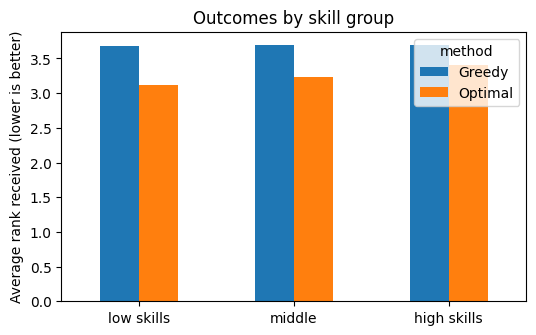

In [8]:
rows = []
for d in data:
    total = d["students"].sum(axis=1)
    group = pd.qcut(total.rank(method="first"), 3, labels=["low skills", "middle", "high skills"])
    for name, ranks in [("Optimal", d["opt"]["rank"]), ("Greedy", d["greedy_rank"])]:
        by = ranks.groupby(group, observed=True).mean()
        rows.append({"seed": d["seed"], "method": name, **by.to_dict()})
sk = pd.DataFrame(rows)

print("Average rank received (lower is better), averaged over 30 datasets:")
tbl = sk.groupby("method")[["low skills", "middle", "high skills"]].mean().round(2)
display(tbl.loc[["Greedy", "Optimal"]])

print("\nGap between low-skills and high-skills students (positive = low-skills students do worse):")
for name in ["Greedy", "Optimal"]:
    s = sk[sk.method == name]
    gap = s["low skills"].values - s["high skills"].values
    lo, hi = interval(pd.Series(gap))
    print(f"  {name:8s} average gap {gap.mean():+.2f} ranks | 95% interval {lo:+.2f} to {hi:+.2f} | "
          f"clearly different from zero: {'yes' if (lo > 0 or hi < 0) else 'no'}")

tbl.loc[["Greedy", "Optimal"]].T.plot(kind="bar", figsize=(6, 3.5))
plt.ylabel("Average rank received (lower is better)")
plt.xticks(rotation=0)
plt.title("Outcomes by skill group")
plt.show()

In [9]:
pd.concat({"Greedy": gr_f, "Optimal": opt_f}, axis=1).round(3).to_csv("fairness_30_datasets.csv")
paired.to_csv("fairness_paired_differences.csv", index=False)
wl.round(2).to_csv("winners_and_losers.csv", index=False)
sk.round(3).to_csv("skill_group_outcomes.csv", index=False)
print("Saved four CSV files")

Saved four CSV files
